# 05. EWMA Temporal Trend Classification

This notebook applies **Exponentially Weighted Moving Average (EWMA)** to the smoothed Product × Aspect × Quarter series.

## Goal

For each product aspect, classify recent temporal behavior as:

- **Improving**
- **Stable**
- **Declining**

EWMA gives more weight to recent quarters while still retaining information from earlier periods.

> The values used for `alpha` and the trend threshold in this notebook are **temporary development settings** for PP1.  
> They must later be tuned and validated using the real Component 1 output.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

WORKSPACE = Path.cwd()
if WORKSPACE.name == "notebooks":
    COMPONENT_ROOT = WORKSPACE.parent
elif (WORKSPACE / "data" / "processed").exists():
    COMPONENT_ROOT = WORKSPACE
else:
    COMPONENT_ROOT = WORKSPACE / "component_3"

INPUT = COMPONENT_ROOT / "data" / "processed" / "paq_smoothed.csv"

OUTPUT_DIR = COMPONENT_ROOT / "data" / "processed"
FIGURE_DIR = COMPONENT_ROOT / "outputs" / "figures"
TABLE_DIR = COMPONENT_ROOT / "outputs" / "tables"

for p in [OUTPUT_DIR, FIGURE_DIR, TABLE_DIR]:
    p.mkdir(parents=True, exist_ok=True)

OUTPUT = OUTPUT_DIR / "paq_with_ewma_trend.csv"

# Temporary PP1 development parameters
DEV_ALPHA = 0.40
DEV_TREND_THRESHOLD = 0.05
DEV_SIGNAL_WINDOW = 2


## 1. Load the smoothed PAQ series


In [2]:
df = pd.read_csv(INPUT)

required = [
    "parent_asin",
    "aspect",
    "quarter",
    "review_count",
    "smoothed_sentiment",
    "temporal_confidence_dev"
]

missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

df["quarter_period"] = pd.PeriodIndex(
    df["quarter"],
    freq="Q"
)

df = (
    df
    .sort_values(
        ["parent_asin", "aspect", "quarter_period"]
    )
    .reset_index(drop=True)
)

print("Rows:", len(df))
print("Products:", df["parent_asin"].nunique())
print("Product-aspect series:", df[["parent_asin", "aspect"]].drop_duplicates().shape[0])

display(df.head())


Rows: 550
Products: 10
Product-aspect series: 50


,parent_asin,aspect,quarter,review_count,mean_sentiment,median_sentiment,positive_rate,neutral_rate,negative_rate,avg_confidence,...,confidence_weighted_sentiment,historical_mean,smoothed_sentiment,smoothing_adjustment,ci_lower,ci_upper,ci_width,temporal_confidence_dev,confidence_label_dev,quarter_period
0,B00FFJ0HUE,battery,2021Q1,3,0.1326,-0.1452,0.3333,0.6667,0.0,0.7348,...,0.1754,0.0000,0.0497,-0.0829,-0.0676,0.2712,0.3387,0.6196,Medium,2021Q1
1,B00FFJ0HUE,battery,2021Q2,3,-0.0371,-0.0177,0.0000,1.0000,0.0,0.7411,...,-0.0449,0.1326,0.0690,0.1061,0.0096,0.1140,0.1044,0.6567,Medium,2021Q2
2,B00FFJ0HUE,battery,2021Q3,5,0.4642,0.4297,0.8000,0.2000,0.0,0.7929,...,0.4900,0.0478,0.2560,-0.2082,0.1394,0.3636,0.2242,0.7042,Medium,2021Q3
3,B00FFJ0HUE,battery,2021Q4,5,0.2114,0.1513,0.4000,0.6000,0.0,0.7260,...,0.2208,0.1866,0.1990,-0.0124,0.1363,0.2866,0.1503,0.6953,Medium,2021Q4
4,B00FFJ0HUE,battery,2022Q1,2,0.0833,0.0833,0.5000,0.0000,0.5,0.8004,...,0.0905,0.1928,0.1615,0.0782,0.0158,0.3072,0.2915,0.6107,Medium,2022Q1


## 2. Apply EWMA per Product × Aspect series

EWMA is calculated independently for every product-aspect pair.

For a series:

`x1, x2, x3, ...`

the EWMA gives greater influence to newer observations.

A larger `alpha` responds faster to recent changes.  
A smaller `alpha` produces a smoother series.


In [3]:
group_cols = ["parent_asin", "aspect"]

df["ewma_sentiment"] = (
    df
    .groupby(group_cols)["smoothed_sentiment"]
    .transform(lambda s: s.ewm(alpha=DEV_ALPHA, adjust=False).mean())
)

df["ewma_change"] = (
    df
    .groupby(group_cols)["ewma_sentiment"]
    .diff()
)

# Use a short recent-change average to reduce one-quarter noise
df["trend_signal"] = (
    df
    .groupby(group_cols)["ewma_change"]
    .transform(lambda s: s.rolling(window=DEV_SIGNAL_WINDOW, min_periods=1).mean())
)

display(
    df[[
        "parent_asin",
        "aspect",
        "quarter",
        "smoothed_sentiment",
        "ewma_sentiment",
        "ewma_change",
        "trend_signal"
    ]].head(20)
)


,parent_asin,aspect,quarter,smoothed_sentiment,ewma_sentiment,ewma_change,trend_signal
0,B00FFJ0HUE,battery,2021Q1,0.0497,0.049700,NaN,NaN
1,B00FFJ0HUE,battery,2021Q2,0.0690,0.057420,0.007720,0.007720
2,B00FFJ0HUE,battery,2021Q3,0.2560,0.136852,0.079432,0.043576
3,B00FFJ0HUE,battery,2021Q4,0.1990,0.161711,0.024859,0.052146
4,B00FFJ0HUE,battery,2022Q1,0.1615,0.161627,-0.000084,0.012387
5,B00FFJ0HUE,battery,2022Q2,0.2876,0.212016,0.050389,0.025152
6,B00FFJ0HUE,battery,2022Q3,0.4333,0.300530,0.088514,0.069451
7,B00FFJ0HUE,battery,2022Q4,0.2768,0.291038,-0.009492,0.039511
8,B00FFJ0HUE,battery,2023Q1,0.3133,0.299943,0.008905,-0.000293
9,B00FFJ0HUE,battery,2023Q2,0.3014,0.300526,0.000583,0.004744


## 3. Classify Improving / Stable / Declining

Temporary development rule:

- `trend_signal >= +0.05` → **Improving**
- `trend_signal <= -0.05` → **Declining**
- otherwise → **Stable**

The threshold is not a final research threshold.


In [4]:
def classify_trend(signal):
    if pd.isna(signal):
        return "Stable"

    if signal >= DEV_TREND_THRESHOLD:
        return "Improving"

    if signal <= -DEV_TREND_THRESHOLD:
        return "Declining"

    return "Stable"

df["trend"] = (
    df["trend_signal"]
    .apply(classify_trend)
)

display(
    df[[
        "parent_asin",
        "aspect",
        "quarter",
        "ewma_sentiment",
        "trend_signal",
        "trend"
    ]].head(30)
)


,parent_asin,aspect,quarter,ewma_sentiment,trend_signal,trend
0,B00FFJ0HUE,battery,2021Q1,0.049700,NaN,Stable
1,B00FFJ0HUE,battery,2021Q2,0.057420,0.007720,Stable
2,B00FFJ0HUE,battery,2021Q3,0.136852,0.043576,Stable
3,B00FFJ0HUE,battery,2021Q4,0.161711,0.052146,Improving
4,B00FFJ0HUE,battery,2022Q1,0.161627,0.012387,Stable
5,B00FFJ0HUE,battery,2022Q2,0.212016,0.025152,Stable
6,B00FFJ0HUE,battery,2022Q3,0.300530,0.069451,Improving
7,B00FFJ0HUE,battery,2022Q4,0.291038,0.039511,Stable
8,B00FFJ0HUE,battery,2023Q1,0.299943,-0.000293,Stable
9,B00FFJ0HUE,battery,2023Q2,0.300526,0.004744,Stable


## 4. Keep uncertainty separate from the trend label

The framework still reports one of the three trend classes.

However, low-support / low-confidence periods are flagged separately so the system does not present the trend with excessive certainty.


In [5]:
def evidence_flag(row):
    if row["review_count"] < 5:
        return "Low Support"

    if row["temporal_confidence_dev"] < 0.60:
        return "Low Confidence"

    return "Adequate"

df["trend_evidence_flag_dev"] = (
    df.apply(
        evidence_flag,
        axis=1
    )
)

display(
    df[[
        "parent_asin",
        "aspect",
        "quarter",
        "review_count",
        "temporal_confidence_dev",
        "trend",
        "trend_evidence_flag_dev"
    ]].head(30)
)


,parent_asin,aspect,quarter,review_count,temporal_confidence_dev,trend,trend_evidence_flag_dev
0,B00FFJ0HUE,battery,2021Q1,3,0.6196,Stable,Low Support
1,B00FFJ0HUE,battery,2021Q2,3,0.6567,Stable,Low Support
2,B00FFJ0HUE,battery,2021Q3,5,0.7042,Stable,Adequate
3,B00FFJ0HUE,battery,2021Q4,5,0.6953,Improving,Adequate
4,B00FFJ0HUE,battery,2022Q1,2,0.6107,Stable,Low Support
5,B00FFJ0HUE,battery,2022Q2,6,0.7044,Stable,Adequate
6,B00FFJ0HUE,battery,2022Q3,6,0.7142,Improving,Adequate
7,B00FFJ0HUE,battery,2022Q4,2,0.6248,Stable,Low Support
8,B00FFJ0HUE,battery,2023Q1,2,0.6484,Stable,Low Support
9,B00FFJ0HUE,battery,2023Q2,1,0.5944,Stable,Low Support


## 5. Latest trend for each Product × Aspect

For PP1, this table is useful because it shows the most recent temporal state for each aspect.


In [6]:
latest = (
    df
    .sort_values("quarter_period")
    .groupby(
        ["parent_asin", "aspect"],
        as_index=False
    )
    .tail(1)
    .copy()
)

latest_table = latest[[
    "parent_asin",
    "aspect",
    "quarter",
    "smoothed_sentiment",
    "ewma_sentiment",
    "trend_signal",
    "trend",
    "temporal_confidence_dev",
    "trend_evidence_flag_dev"
]].copy()

latest_table.to_csv(
    TABLE_DIR / "latest_ewma_trends.csv",
    index=False
)

display(
    latest_table
    .sort_values(
        ["trend", "trend_signal"]
    )
)


,parent_asin,aspect,quarter,smoothed_sentiment,ewma_sentiment,trend_signal,trend,temporal_confidence_dev,trend_evidence_flag_dev
395,B01MPXRXR0,battery,2023Q3,-0.2698,-0.027581,-0.117039,Declining,0.7854,Adequate
329,B019BX7F86,thermal,2023Q3,-0.0823,0.058573,-0.091721,Declining,0.7684,Adequate
384,B01K1IO3QW,thermal,2023Q3,-0.2902,-0.141940,-0.075453,Declining,0.7730,Adequate
472,B07GM2J11Q,keyboard,2023Q3,0.3325,0.322110,-0.050431,Declining,0.7717,Adequate
153,B00L49X8E6,performance,2023Q3,0.1677,0.243540,-0.049446,Stable,0.7569,Adequate
340,B01K1IO3QW,battery,2023Q3,0.1413,0.215236,-0.037688,Stable,0.7594,Adequate
549,B0C2ZMJW53,thermal,2023Q3,0.3897,0.398223,-0.035376,Stable,0.7336,Adequate
98,B00KB7O49K,performance,2023Q3,0.2955,0.351640,-0.024869,Stable,0.6924,Adequate
538,B0C2ZMJW53,performance,2023Q3,0.1247,0.214913,-0.024556,Stable,0.7775,Adequate
274,B00TW47DSW,thermal,2023Q3,0.2522,0.333293,-0.024116,Stable,0.7496,Adequate


## 6. Trend distribution


,trend,count
0,Improving,0
1,Stable,46
2,Declining,4


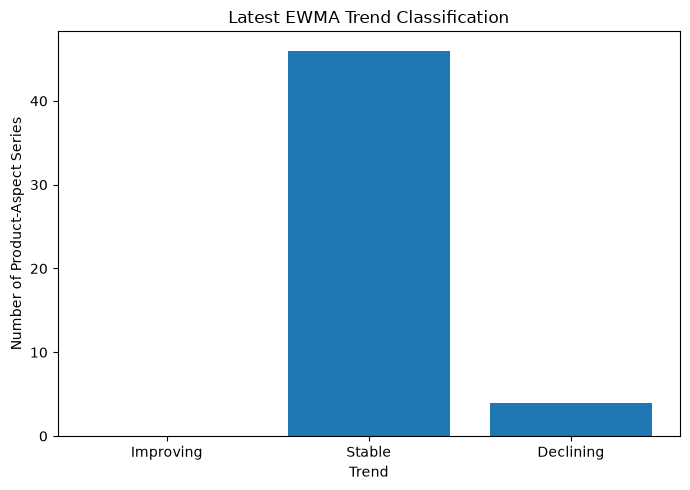

In [7]:
trend_counts = (
    latest_table["trend"]
    .value_counts()
    .reindex(
        ["Improving", "Stable", "Declining"],
        fill_value=0
    )
)

display(
    trend_counts
    .rename("count")
    .reset_index()
    .rename(columns={"index": "trend"})
)

plt.figure(figsize=(7, 5))

plt.bar(
    trend_counts.index,
    trend_counts.values
)

plt.title("Latest EWMA Trend Classification")
plt.xlabel("Trend")
plt.ylabel("Number of Product-Aspect Series")
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "latest_ewma_trend_distribution.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()


## 7. Plot one strong decline example

The notebook automatically selects the latest product-aspect series with the most negative trend signal.

This gives a useful PP1 proof-of-concept figure without hard-coding a product.


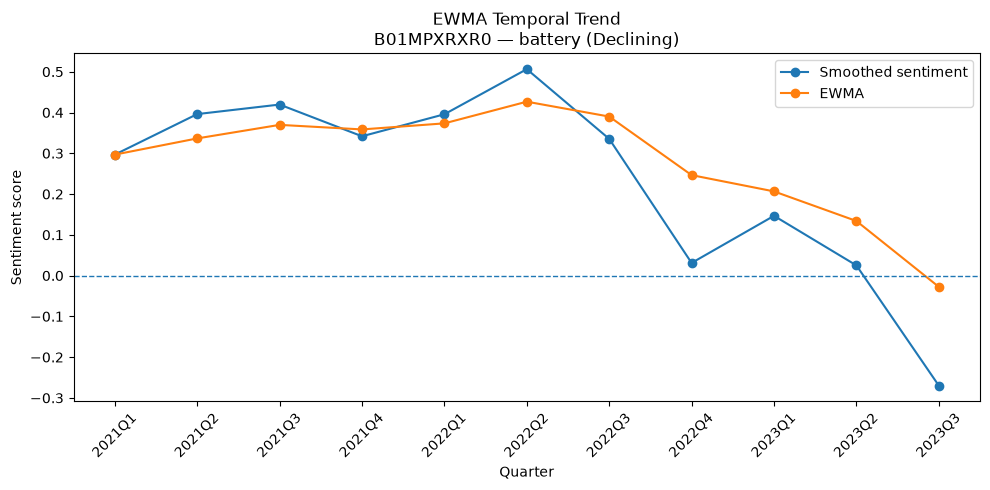

Example product: B01MPXRXR0
Example aspect : battery
Latest trend   : Declining
Trend signal   : -0.117


In [8]:
decline_candidates = (
    latest_table
    .sort_values("trend_signal")
)

example_row = decline_candidates.iloc[0]

example_product = example_row["parent_asin"]
example_aspect = example_row["aspect"]

example = df[
    (df["parent_asin"] == example_product)
    & (df["aspect"] == example_aspect)
].copy()

example = example.sort_values("quarter_period")

plt.figure(figsize=(10, 5))

plt.plot(
    example["quarter"],
    example["smoothed_sentiment"],
    marker="o",
    label="Smoothed sentiment"
)

plt.plot(
    example["quarter"],
    example["ewma_sentiment"],
    marker="o",
    label="EWMA"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title(
    f"EWMA Temporal Trend\n"
    f"{example_product} — {example_aspect} "
    f"({example_row['trend']})"
)

plt.xlabel("Quarter")
plt.ylabel("Sentiment score")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "ewma_decline_example.png",
    dpi=180,
    bbox_inches="tight"
)

plt.show()

print("Example product:", example_product)
print("Example aspect :", example_aspect)
print("Latest trend   :", example_row["trend"])
print("Trend signal   :", round(example_row["trend_signal"], 4))


## 8. Save the EWMA trend table


In [9]:
df = df.drop(
    columns=["quarter_period"]
)

numeric_columns = [
    "ewma_sentiment",
    "ewma_change",
    "trend_signal"
]

for c in numeric_columns:
    df[c] = df[c].round(4)

df.to_csv(
    OUTPUT,
    index=False
)

print("Saved:", OUTPUT)
print("Rows:", len(df))


Saved: c:\Users\victus\Desktop\Repository\J26-DS-349\component_3\data\processed\paq_with_ewma_trend.csv
Rows: 550
